# 4.1. Análisis exploratorio de datos

## Proyecto OSIPTEL: monitoreo de la brecha digital y las conexiones de internet fijo en el Perú

### Objetivo

Analizar la evolución de las conexiones de internet fijo,
identificar diferencias territoriales, evaluar la transición
tecnológica y detectar variaciones relevantes que permitan
priorizar acciones de seguimiento.

### Alcance metodológico

- Histórico nacional: diciembre de 1999 a marzo de 2026.
- Análisis territorial: marzo de 2016 a marzo de 2026.
- Fibra óptica: marzo de 2023 a marzo de 2026.
- Indicadores INEI: únicamente trimestres verificados.
- Las conexiones representan cantidades existentes al
  cierre de cada periodo, no nuevos usuarios acumulados.
- Las conexiones fijas no equivalen al porcentaje de
  hogares con acceso a internet.
- Los registros documentales pendientes y conflictivos
  quedan excluidos de los indicadores analíticos.

In [1]:
from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

spark = (
    SparkSession.builder
    .appName("OSIPTEL_EDA")
    .master("local[2]")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (13, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "figure.dpi": 110
})

PROYECTO = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "run_pipeline.py").is_file()
    and (p / "notebooks").is_dir()
)

BASE = PROYECTO / "data" / "paquete_20261125_c5cc727"
RESULTADOS = PROYECTO / "results" / "eda"

RESULTADOS.mkdir(parents=True, exist_ok=True)

def cargar(nombre):
    return spark.read.parquet((BASE / nombre).as_uri())

f1_nacional = cargar("f1_historico_nacional")
f1_territorial = cargar("f1_historico_territorial")
f2 = cargar("f2_menciones_verificadas")
f3 = cargar("f3_cifras_contextualizadas")
f4 = cargar("f4_hogares_verificados")
comparacion = cargar("comparacion_f1_f4")

territorial = f1_territorial.filter(
    F.col("periodo").between("2016-03", "2026-03")
)

def guardar_grafico(nombre):
    plt.tight_layout()
    plt.savefig(
        RESULTADOS / f"{nombre}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("Entorno analitico preparado")
print("Spark:", spark.version)
print("Resultados:", RESULTADOS)

26/11/27 12:00:19 WARN Utils: Your hostname, debian resolves to a loopback address: 127.0.0.1; using 10.0.2.15 instead (on interface enp0s3)
26/11/27 12:00:19 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/27 12:00:20 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/27 12:00:20 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Entorno analitico preparado
Spark: 3.5.1
Resultados: /home/nevado/BigData_UPAO/OSIPTEL_Analisis_Final/results/eda


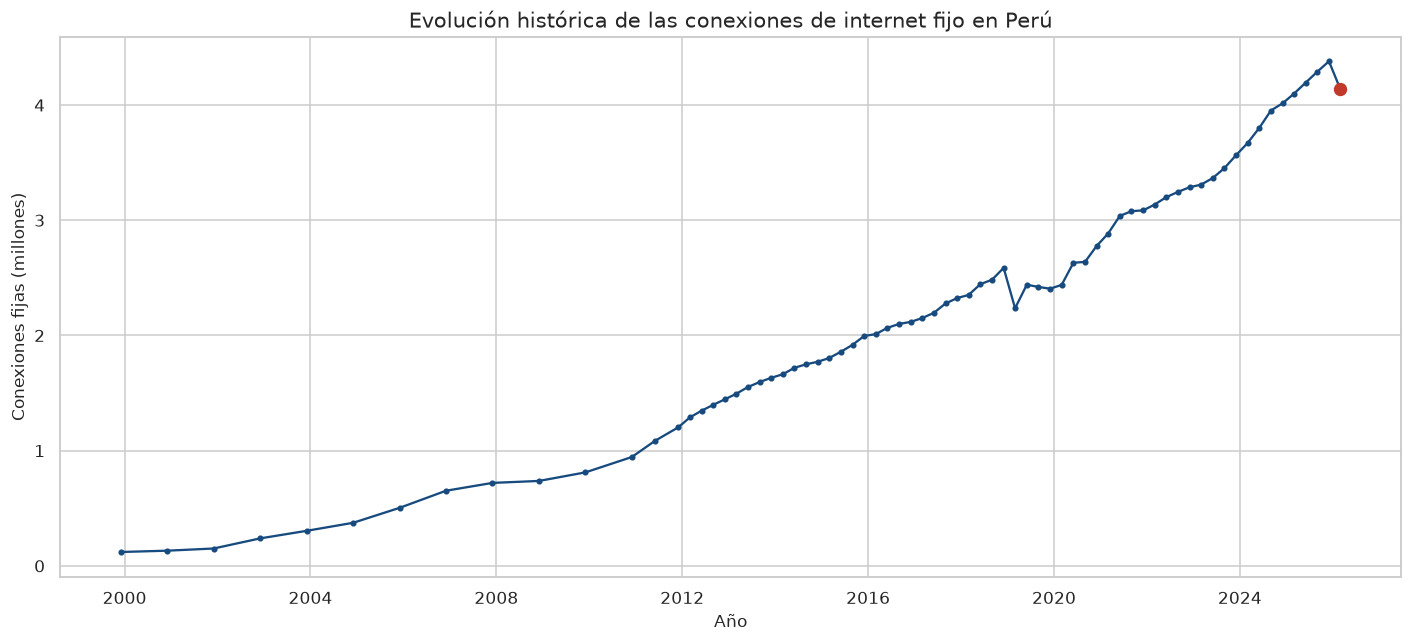

,periodo,conexiones_fijas,intervalo_meses,variacion_pct
59,2023-06,3365379,3.0,1.72
60,2023-09,3451991,3.0,2.57
61,2023-12,3563247,3.0,3.22
62,2024-03,3669365,3.0,2.98
63,2024-06,3800822,3.0,3.58
64,2024-09,3952448,3.0,3.99
65,2024-12,4014572,3.0,1.57
66,2025-03,4098323,3.0,2.09
67,2025-06,4194402,3.0,2.34
68,2025-09,4289604,3.0,2.27


In [2]:
nacional = (
    f1_nacional
    .select("periodo", "conexiones_fijas")
    .orderBy("periodo")
    .toPandas()
)

nacional["fecha"] = pd.to_datetime(
    nacional["periodo"], format="%Y-%m"
)

nacional["variacion_pct"] = (
    nacional["conexiones_fijas"].pct_change() * 100
)

nacional["intervalo_meses"] = (
    nacional["fecha"].dt.year * 12
    + nacional["fecha"].dt.month
).diff()

fig, ax = plt.subplots()

ax.plot(
    nacional["fecha"],
    nacional["conexiones_fijas"] / 1_000_000,
    color="#174A7E",
    marker="o",
    markersize=3
)

ax.set_title("Evolución histórica de las conexiones de internet fijo en Perú")
ax.set_xlabel("Año")
ax.set_ylabel("Conexiones fijas (millones)")

ultimo = nacional.iloc[-1]

ax.scatter(
    ultimo["fecha"],
    ultimo["conexiones_fijas"] / 1_000_000,
    color="#C0392B",
    s=60,
    zorder=5
)

guardar_grafico("01_evolucion_nacional")

display(
    nacional[
        ["periodo", "conexiones_fijas",
         "intervalo_meses", "variacion_pct"]
    ].tail(12).round(2)
)

nacional.to_csv(
    RESULTADOS / "evolucion_nacional.csv", index=False
)

### Interpretación

Las conexiones de internet fijo presentan una tendencia creciente desde 1999 hasta finales de 2025. Sin embargo, en marzo de 2026 se registra una disminución de 243.549 conexiones respecto al trimestre anterior, equivalente al 5,56 %.

Esta disminución interrumpe el crecimiento de los últimos trimestres, por lo que resulta necesario identificar los operadores, tecnologías y departamentos donde se concentra esta variación.

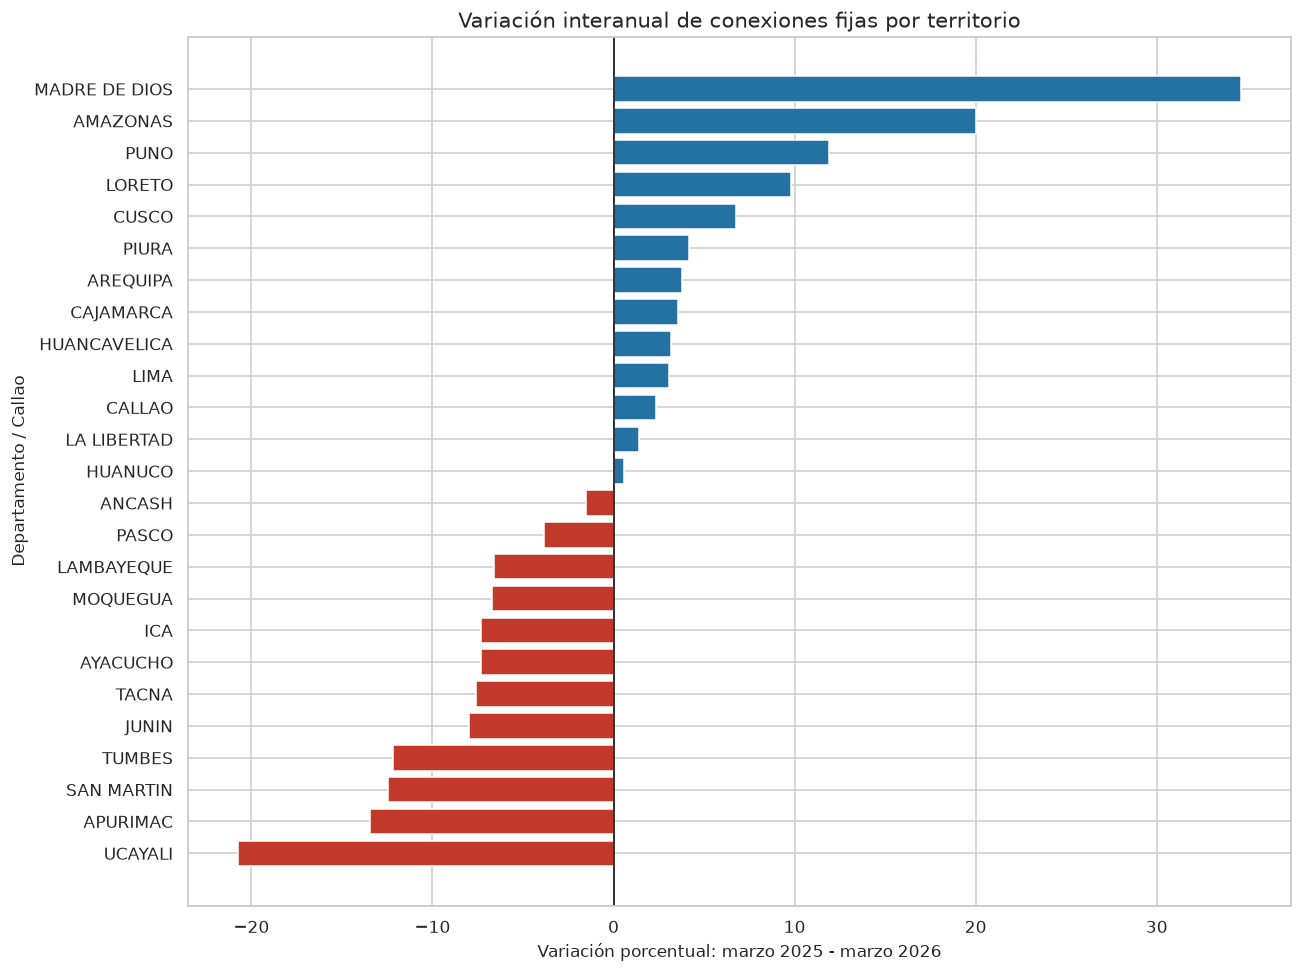

,conexiones_2016,conexiones_2025,conexiones_2026,crecimiento_historico_pct,crecimiento_interanual_pct
departamento,,,,,
UCAYALI,12832,70050,55514,332.62,-20.75
APURIMAC,5477,22180,19198,250.52,-13.44
SAN MARTIN,15748,59457,52039,230.45,-12.48
TUMBES,9340,43974,38610,313.38,-12.20
JUNIN,44867,107975,99378,121.49,-7.96
TACNA,27437,56221,51948,89.34,-7.60
AYACUCHO,12395,43990,40762,228.86,-7.34
ICA,45665,158442,146878,221.64,-7.30
MOQUEGUA,10914,31365,29256,168.06,-6.72


In [3]:
panel = (
    territorial
    .groupBy("periodo", "departamento")
    .agg(
        F.sum("conexiones_fijas").alias("conexiones")
    )
    .orderBy("departamento", "periodo")
    .toPandas()
)

panel["fecha"] = pd.to_datetime(panel["periodo"])

assert len(panel) == 1025

tabla = panel.pivot(
    index="departamento",
    columns="periodo",
    values="conexiones"
)

ranking = pd.DataFrame({
    "conexiones_2016": tabla["2016-03"],
    "conexiones_2025": tabla["2025-03"],
    "conexiones_2026": tabla["2026-03"]
})

ranking["crecimiento_historico_pct"] = (
    ranking["conexiones_2026"]
    / ranking["conexiones_2016"].replace(0, np.nan)
    - 1
) * 100

ranking["crecimiento_interanual_pct"] = (
    ranking["conexiones_2026"]
    / ranking["conexiones_2025"].replace(0, np.nan)
    - 1
) * 100

ranking = ranking.sort_values(
    "crecimiento_interanual_pct"
)

colores = [
    "#C0392B" if valor < 0 else "#2471A3"
    for valor in ranking["crecimiento_interanual_pct"]
]

plt.figure(figsize=(12, 9))

plt.barh(
    ranking.index,
    ranking["crecimiento_interanual_pct"],
    color=colores
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Variación interanual de conexiones fijas por territorio")
plt.xlabel("Variación porcentual: marzo 2025 - marzo 2026")
plt.ylabel("Departamento / Callao")

guardar_grafico("02_crecimiento_territorial")

display(ranking.round(2))

ranking.to_csv(RESULTADOS / "crecimiento_territorial.csv")
panel.to_csv(
    RESULTADOS / "panel_departamento_trimestre.csv",
    index=False
)

### Interpretación

De las 25 unidades territoriales analizadas, 12 presentan una disminución interanual en las conexiones fijas reportadas. Ucayali registra la mayor reducción con un 20,75 %, seguido de Apurímac, San Martín y Tumbes.

Por otro lado, Madre de Dios y Amazonas presentan los mayores crecimientos, con 34,67 % y 20,02 %, respectivamente. La Libertad registra un crecimiento del 1,42 %.

Estos resultados permiten identificar territorios que requieren un seguimiento prioritario. Sin embargo, no representan directamente la cobertura ni la penetración del servicio, debido a que no se dispone de información sobre la cantidad de hogares por departamento.

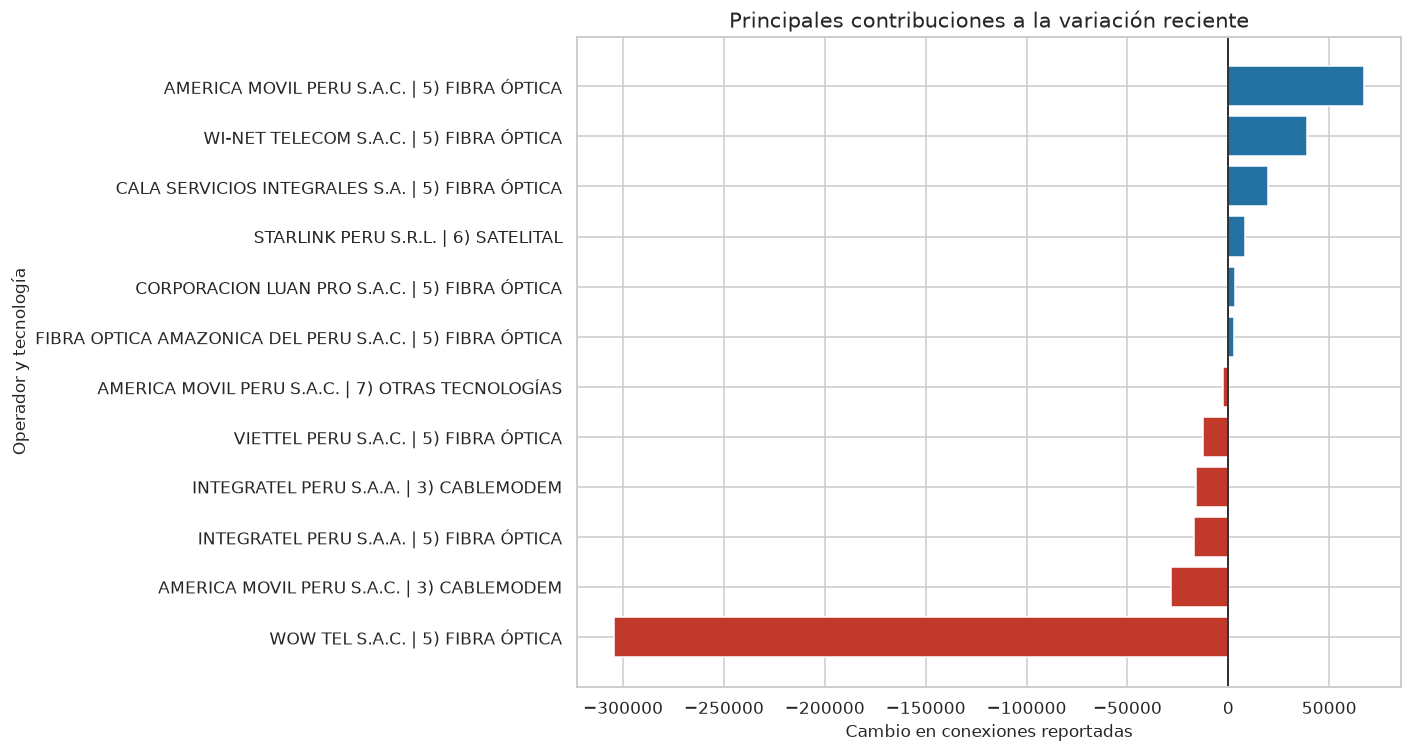

Variacion nacional reconstruida: -243549.0


periodo,operador,tecnologia,2025-12,2026-03,estado_reporte,variacion_reportada
140,WOW TEL S.A.C.,5) FIBRA ÓPTICA,809557.0,505271.0,Presente en ambos cortes,-304286.0
0,AMERICA MOVIL PERU S.A.C.,3) CABLEMODEM,436153.0,407705.0,Presente en ambos cortes,-28448.0
78,INTEGRATEL PERU S.A.A.,5) FIBRA ÓPTICA,874926.0,857941.0,Presente en ambos cortes,-16985.0
77,INTEGRATEL PERU S.A.A.,3) CABLEMODEM,176948.0,160721.0,Presente en ambos cortes,-16227.0
137,VIETTEL PERU S.A.C.,5) FIBRA ÓPTICA,64171.0,51591.0,Presente en ambos cortes,-12580.0
2,AMERICA MOVIL PERU S.A.C.,7) OTRAS TECNOLOGÍAS,34570.0,32012.0,Presente en ambos cortes,-2558.0
27,CABLENORTV S.A.C.,5) FIBRA ÓPTICA,2168.0,376.0,Presente en ambos cortes,-1792.0
76,INTEGRATEL PERU S.A.A.,2) XDSL,12965.0,11341.0,Presente en ambos cortes,-1624.0
52,ENTEL PERU S.A.,7) OTRAS TECNOLOGÍAS,14756.0,13272.0,Presente en ambos cortes,-1484.0
144,ZAAZ PERU S.A.C.,5) FIBRA ÓPTICA,67997.0,66844.0,Presente en ambos cortes,-1153.0


ESTADOS DE DISPONIBILIDAD


,estado_reporte,Combinaciones
0,Presente en ambos cortes,142
1,Solo presente en diciembre 2025,2
2,Solo presente en marzo 2026,1


In [4]:
detalle = (
    territorial
    .filter(F.col("periodo").isin("2025-12", "2026-03"))
    .groupBy("periodo", "operador", "tecnologia")
    .agg(
        F.sum("conexiones_fijas").alias("conexiones")
    )
    .toPandas()
)

cambios = detalle.pivot(
    index=["operador", "tecnologia"],
    columns="periodo",
    values="conexiones"
).reset_index()

cambios["estado_reporte"] = np.select(
    [
        cambios["2025-12"].isna(),
        cambios["2026-03"].isna()
    ],
    [
        "Solo presente en marzo 2026",
        "Solo presente en diciembre 2025"
    ],
    default="Presente en ambos cortes"
)

cambios["variacion_reportada"] = (
    cambios["2026-03"].fillna(0)
    - cambios["2025-12"].fillna(0)
)

cambios = cambios.sort_values("variacion_reportada")

principales = cambios.loc[
    cambios["variacion_reportada"]
    .abs()
    .nlargest(12)
    .index
].sort_values("variacion_reportada")

etiquetas = (
    principales["operador"]
    + " | "
    + principales["tecnologia"]
)

colores = [
    "#C0392B" if v < 0 else "#2471A3"
    for v in principales["variacion_reportada"]
]

plt.figure(figsize=(13, 7))

plt.barh(
    etiquetas,
    principales["variacion_reportada"],
    color=colores
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Principales contribuciones a la variación reciente")
plt.xlabel("Cambio en conexiones reportadas")
plt.ylabel("Operador y tecnología")

guardar_grafico("03_descomposicion_variacion")

print(
    "Variacion nacional reconstruida:",
    cambios["variacion_reportada"].sum()
)

display(cambios.head(15))

print("ESTADOS DE DISPONIBILIDAD")

display(
    cambios.groupby("estado_reporte")
    .size()
    .reset_index(name="Combinaciones")
)

cambios.to_csv(
    RESULTADOS / "variacion_operador_tecnologia.csv",
    index=False
)

### Interpretación

La principal contribución negativa a la variación nacional corresponde a WOW TEL S.A.C. en la categoría de fibra óptica, cuyos registros disminuyeron en 304.286 conexiones entre diciembre de 2025 y marzo de 2026.

También se identificaron disminuciones en América Móvil, Integratel y Viettel. Sin embargo, el crecimiento de otras combinaciones de operadores y tecnologías compensó parcialmente estas reducciones.

Este resultado permite orientar el seguimiento hacia operadores específicos. No obstante, se necesita revisar los reportes originales para determinar si las disminuciones corresponden a bajas efectivas del servicio o cambios en la información reportada.

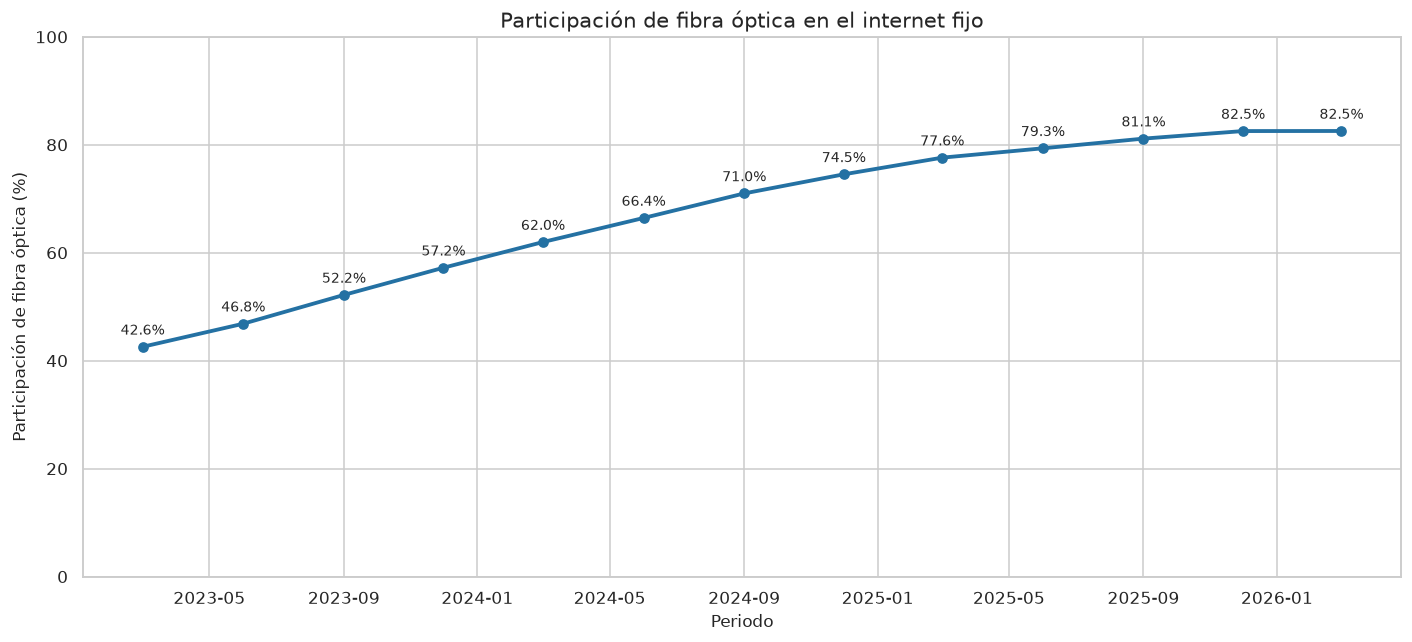

,periodo,total_conexiones,conexiones_fibra,participacion_fibra_pct
0,2023-03,3308611,1408103,42.56
1,2023-06,3365379,1576258,46.84
2,2023-09,3451991,1800884,52.17
3,2023-12,3563247,2038468,57.21
4,2024-03,3669365,2273858,61.97
5,2024-06,3800822,2524774,66.43
6,2024-09,3952448,2805363,70.98
7,2024-12,4014572,2991439,74.51
8,2025-03,4098323,3180504,77.61
9,2025-06,4194402,3327714,79.34


In [5]:
fibra = (
    territorial
    .filter(
        F.col("periodo").between("2023-03", "2026-03")
    )
    .groupBy("periodo")
    .agg(
        F.sum("conexiones_fijas").alias("total_conexiones"),

        F.sum(
            F.when(
                F.col("tecnologia") == "5) FIBRA ÓPTICA",
                F.col("conexiones_fijas")
            )
        ).alias("conexiones_fibra")
    )
    .orderBy("periodo")
    .toPandas()
)

fibra["fecha"] = pd.to_datetime(fibra["periodo"])

fibra["participacion_fibra_pct"] = (
    fibra["conexiones_fibra"]
    / fibra["total_conexiones"].replace(0, np.nan)
) * 100

plt.figure(figsize=(13, 6))

plt.plot(
    fibra["fecha"],
    fibra["participacion_fibra_pct"],
    marker="o",
    linewidth=2.5,
    color="#2471A3"
)

for _, fila in fibra.iterrows():
    if pd.notna(fila["participacion_fibra_pct"]):
        plt.annotate(
            f'{fila["participacion_fibra_pct"]:.1f}%',
            (
                fila["fecha"],
                fila["participacion_fibra_pct"]
            ),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

plt.title("Participación de fibra óptica en el internet fijo")
plt.xlabel("Periodo")
plt.ylabel("Participación de fibra óptica (%)")
plt.ylim(0, 100)

guardar_grafico("04_evolucion_fibra_optica")

display(
    fibra[
        ["periodo", "total_conexiones",
         "conexiones_fibra", "participacion_fibra_pct"]
    ].round(2)
)

fibra.to_csv(
    RESULTADOS / "participacion_fibra.csv",
    index=False
)

### Interpretación

La participación de fibra óptica aumentó del 42,56 % en marzo de 2023 al 82,55 % en marzo de 2026, mostrando un cambio importante en la composición tecnológica del internet fijo en el Perú.

Sin embargo, durante el último trimestre, la cantidad de conexiones de fibra óptica disminuyó de 3.614.437 a 3.414.062, mientras que su participación porcentual permaneció prácticamente estable.

Esto demuestra la importancia de analizar tanto las cantidades absolutas como los porcentajes. El análisis comienza en marzo de 2023 porque anteriormente la fibra óptica no aparece como categoría independiente en los datos entregados.

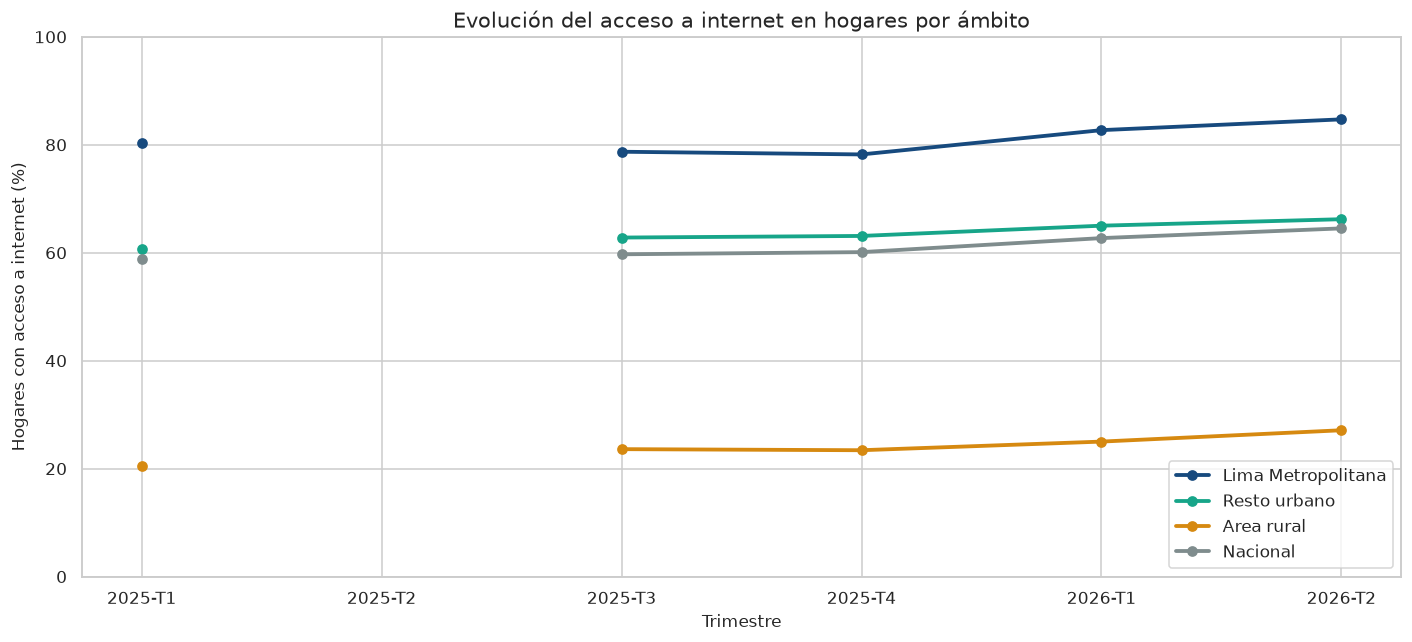

ambito,Area rural,Lima Metropolitana,Nacional,Resto urbano,brecha_lima_rural_pp,brecha_urbano_rural_pp
2025Q1,20.5,80.3,58.9,60.7,59.8,40.2
2025Q2,NaN,NaN,NaN,NaN,NaN,NaN
2025Q3,23.6,78.7,59.7,62.8,55.1,39.2
2025Q4,23.4,78.2,60.1,63.1,54.8,39.7
2026Q1,25.0,82.7,62.7,65.0,57.7,40.0
2026Q2,27.1,84.7,64.5,66.2,57.6,39.1


In [6]:
hogares = (
    f4.select("periodo", "ambito", "porcentaje")
    .toPandas()
)

hogares["trimestre"] = pd.PeriodIndex(
    hogares["periodo"].str.replace("T", "Q"),
    freq="Q"
)

brecha = hogares.pivot(
    index="trimestre",
    columns="ambito",
    values="porcentaje"
).sort_index()

indice = pd.period_range(
    brecha.index.min(),
    brecha.index.max(),
    freq="Q"
)

brecha = brecha.reindex(indice)

brecha["brecha_lima_rural_pp"] = (
    brecha["Lima Metropolitana"] - brecha["Area rural"]
)

brecha["brecha_urbano_rural_pp"] = (
    brecha["Resto urbano"] - brecha["Area rural"]
)

etiquetas = [
    str(p).replace("Q", "-T")
    for p in brecha.index
]

plt.figure(figsize=(13, 6))

for ambito, color in [
    ("Lima Metropolitana", "#174A7E"),
    ("Resto urbano", "#17A589"),
    ("Area rural", "#D68910"),
    ("Nacional", "#7F8C8D")
]:

    plt.plot(
        etiquetas,
        brecha[ambito],
        marker="o",
        linewidth=2.5,
        label=ambito,
        color=color
    )

plt.title("Evolución del acceso a internet en hogares por ámbito")
plt.xlabel("Trimestre")
plt.ylabel("Hogares con acceso a internet (%)")
plt.ylim(0, 100)
plt.legend()

guardar_grafico("05_brecha_digital")

display(brecha.round(2))

brecha.to_csv(
    RESULTADOS / "brecha_digital_inei.csv"
)

### Interpretación

En el segundo trimestre de 2026, Lima Metropolitana presenta un 84,7 % de hogares con acceso a internet, mientras que el área rural alcanza un 27,1 %, existiendo una diferencia de 57,6 puntos porcentuales.

Aunque el acceso a internet en las zonas rurales ha aumentado desde el primer trimestre de 2025, todavía existe una diferencia considerable respecto a los ámbitos urbanos.

A diferencia de los gráficos anteriores, este indicador del INEI mide el acceso a internet en los hogares y no exclusivamente las conexiones de internet fijo. Asimismo, se conserva el vacío correspondiente al segundo trimestre de 2025 debido a la ausencia de información verificada.

In [7]:
print("COMPARACION NACIONAL OSIPTEL - INEI")

contraste = (
    comparacion
    .select(
        "periodo_trimestre",
        "periodo_cierre_f1",
        "conexiones_fijas_f1",
        "hogares_internet_pct_f4",
        "estado_cobertura",
        "tipo_comparacion"
    )
    .orderBy("periodo_trimestre")
    .toPandas()
)

display(contraste)

print("\nF3 - CIFRAS ESTADISTICAS CONTEXTUALIZADAS")

evidencia_f3 = (
    f3.select(
        "indicador_corregido",
        "valor",
        "unidad",
        "periodo_validado",
        "ambito_o_entidad",
        "naturaleza",
        "interpretacion_verificada",
        "documento_pdf",
        "pagina_pdf"
    )
    .toPandas()
)

display(evidencia_f3)

print("\nF2 - CONTEXTO REGULATORIO")

contexto_f2 = (
    f2.groupBy("tipo_hecho")
    .agg(
        F.count("*").alias("menciones"),
        F.countDistinct("documento").alias("documentos_distintos")
    )
    .orderBy(F.desc("menciones"))
    .toPandas()
)

display(contexto_f2)

print("\nESTADO DE APROBACION DE MANDATOS")

display(
    f2.groupBy(
        "apto_como_mandato_aprobado",
        "aprobacion_institucional"
    ).count().toPandas()
)

contraste.to_csv(
    RESULTADOS / "contraste_osiptel_inei.csv",
    index=False
)

evidencia_f3.to_csv(
    RESULTADOS / "evidencia_estadistica_f3.csv",
    index=False
)

contexto_f2.to_csv(
    RESULTADOS / "contexto_regulatorio_f2.csv",
    index=False
)

COMPARACION NACIONAL OSIPTEL - INEI


,periodo_trimestre,periodo_cierre_f1,conexiones_fijas_f1,hogares_internet_pct_f4,estado_cobertura,tipo_comparacion
0,2025-T1,2025-03,4098323.0,58.9,AMBAS_FUENTES,DESCRIPTIVA_NO_CAUSAL
1,2025-T3,2025-09,4289604.0,59.7,AMBAS_FUENTES,DESCRIPTIVA_NO_CAUSAL
2,2025-T4,2025-12,4379544.0,60.1,AMBAS_FUENTES,DESCRIPTIVA_NO_CAUSAL
3,2026-T1,2026-03,4135995.0,62.7,AMBAS_FUENTES,DESCRIPTIVA_NO_CAUSAL
4,2026-T2,None,NaN,64.5,SOLO_INEI,DESCRIPTIVA_NO_CAUSAL



F3 - CIFRAS ESTADISTICAS CONTEXTUALIZADAS


,indicador_corregido,valor,unidad,periodo_validado,ambito_o_entidad,naturaleza,interpretacion_verificada,documento_pdf,pagina_pdf
0,VARIACION_INTERANUAL_CONEXIONES_FIJAS,47.95,porcentaje,2022-06,Huancavelica,VARIACION,Tasa positiva interanual vs 2021-06,5905738-reporte-estadistico-agosto-2022.pdf,4
1,VARIACION_INTERANUAL_CONEXIONES_FIJAS,30.66,porcentaje,2022-06,Ica,VARIACION,Tasa positiva interanual vs 2021-06,5905738-reporte-estadistico-agosto-2022.pdf,4
2,VARIACION_INTERANUAL_CONEXIONES_FIJAS,22.62,porcentaje,2022-06,Apurimac,VARIACION,Tasa positiva interanual vs 2021-06,5905738-reporte-estadistico-agosto-2022.pdf,4
3,VARIACION_INTERANUAL_CONEXIONES_FIJAS,18.12,porcentaje,2022-06,Lambayeque,VARIACION,Tasa positiva interanual vs 2021-06,5905738-reporte-estadistico-agosto-2022.pdf,4
4,CONEXIONES_FIJAS_GRUPO_OPERADORES,332829.00,conexiones,2023-03,Nacional / grupo WI-NET y Optical Technologies,STOCK_PARCIAL,Existencia del grupo operador al cierre de mar...,5905845-reporte-estadistico-n-05-mayo-2023.pdf,2
5,DISMINUCION_INTERANUAL_CONEXIONES_OPERADOR,244206.00,conexiones,2023-06,Nacional / Telefonica,VARIACION_ABSOLUTA,Caida vs junio 2022; no es stock de conexiones,5905857-reporte-estadistico-n-06-agosto-2023.pdf,2
6,CONEXIONES_FIJAS_TOTAL_NACIONAL,3540474.00,conexiones,2023-12,Nacional,STOCK_NACIONAL,Existencia total nacional a diciembre 2023,5905919-reporte-estadistico-n-01-febrero-2024.pdf,4
7,CONEXIONES_FIJAS_FIBRA_OPTICA_NACIONAL,2540374.00,conexiones,2024-06,Nacional / fibra optica,STOCK_TECNOLOGIA,Existencia de conexiones con fibra optica; no ...,5905973-reporte-estadistico-n-07-agosto-2024.pdf,1
8,CONEXIONES_FIJAS_FIBRA_OPTICA_NACIONAL,2783379.00,conexiones,2024-09,Nacional / fibra optica,STOCK_TECNOLOGIA,Existencia de conexiones con fibra optica; no ...,6644026-reporte-estadistico-n-11-noviembre-202...,1
9,DISMINUCION_INTERANUAL_CONEXIONES_OPERADOR,153363.00,conexiones,2025-03,Nacional / Telefonica del Peru,VARIACION_ABSOLUTA,Caida desde marzo 2024; no es stock de conexiones,7801986-reporte-estadistico-n-04-mayo-2025.pdf,2



F2 - CONTEXTO REGULATORIO


,tipo_hecho,menciones,documentos_distintos
0,INFRAESTRUCTURA_COMPARTIDA,88,88
1,SOLICITUD_MANDATO,73,73
2,CONDICION_ECONOMICA_MENCIONADA,71,71
3,PROYECTO_MANDATO,40,40
4,EVALUACION_SOLICITUD,15,15



ESTADO DE APROBACION DE MANDATOS


,apto_como_mandato_aprobado,aprobacion_institucional,count
0,NO,NO_CONSTA,287


In [8]:
tipos_stock = {
    "CONEXIONES_FIJAS_TOTAL_NACIONAL",
    "CONEXIONES_FIJAS_FIBRA_OPTICA_NACIONAL"
}

contraste_f3 = evidencia_f3[
    evidencia_f3["indicador_corregido"].isin(tipos_stock)
].copy()

stock_nacional = nacional.set_index(
    "periodo"
)["conexiones_fijas"]

stock_fibra = fibra.set_index(
    "periodo"
)["conexiones_fibra"]

def obtener_valor_f1(fila):

    periodo = fila["periodo_validado"]

    if fila["indicador_corregido"] == \
            "CONEXIONES_FIJAS_TOTAL_NACIONAL":
        return stock_nacional.get(periodo, np.nan)

    return stock_fibra.get(periodo, np.nan)

contraste_f3["valor_f1"] = contraste_f3.apply(
    obtener_valor_f1, axis=1
)

contraste_f3["diferencia_absoluta"] = (
    contraste_f3["valor_f1"] - contraste_f3["valor"]
)

contraste_f3["diferencia_pct"] = (
    contraste_f3["diferencia_absoluta"]
    / contraste_f3["valor"].replace(0, np.nan)
) * 100

display(
    contraste_f3[[
        "indicador_corregido",
        "periodo_validado",
        "valor_f1",
        "valor",
        "diferencia_absoluta",
        "diferencia_pct",
        "documento_pdf",
        "pagina_pdf"
    ]].round(2)
)

contraste_f3.to_csv(
    RESULTADOS / "contraste_cuantitativo_f1_f3.csv",
    index=False
)

,indicador_corregido,periodo_validado,valor_f1,valor,diferencia_absoluta,diferencia_pct,documento_pdf,pagina_pdf
6,CONEXIONES_FIJAS_TOTAL_NACIONAL,2023-12,3563247,3540474.0,22773.0,0.64,5905919-reporte-estadistico-n-01-febrero-2024.pdf,4
7,CONEXIONES_FIJAS_FIBRA_OPTICA_NACIONAL,2024-06,2524774,2540374.0,-15600.0,-0.61,5905973-reporte-estadistico-n-07-agosto-2024.pdf,1
8,CONEXIONES_FIJAS_FIBRA_OPTICA_NACIONAL,2024-09,2805363,2783379.0,21984.0,0.79,6644026-reporte-estadistico-n-11-noviembre-202...,1
10,CONEXIONES_FIJAS_TOTAL_NACIONAL,2025-09,4289604,4274935.0,14669.0,0.34,7802440-reporte-estadistico-n-07.pdf,1


### Contraste e integración de fuentes

La comparación entre los registros históricos de OSIPTEL y sus reportes estadísticos evidencia diferencias en algunas cantidades de conexiones correspondientes al mismo periodo e indicador.

Para mantener la consistencia temporal del análisis, se utiliza F1 como fuente principal de los indicadores históricos y del modelado predictivo. F3 se conserva como fuente de contraste documental, sin sustituir ni combinar directamente sus valores con los de F1.

Asimismo, F2 proporciona contexto regulatorio mediante 287 menciones verificadas. Ninguna de ellas ha sido clasificada como evidencia suficiente de un mandato aprobado, por lo que no se utiliza para contabilizar proyectos ejecutados.

La integración con F4 permite contextualizar la evolución de las conexiones fijas frente al acceso a internet en los hogares, manteniendo las diferencias de unidad, alcance y significado entre ambos indicadores.

## Conclusiones del análisis exploratorio

El análisis permitió identificar una tendencia histórica de crecimiento de las conexiones de internet fijo en el Perú, acompañada de una transición tecnológica hacia la fibra óptica.

Sin embargo, la disminución observada en marzo de 2026 y las diferencias de crecimiento entre departamentos evidencian la necesidad de contar con mecanismos de seguimiento y alerta temprana.

La descomposición de las variaciones por operador y tecnología permite orientar las revisiones hacia segmentos específicos del mercado, mientras que los indicadores del INEI permiten contextualizar las diferencias de acceso a internet entre ámbitos urbanos y rurales.

A partir de estos hallazgos, se propone desarrollar un modelo predictivo que estime la cantidad de conexiones fijas del siguiente trimestre por unidad territorial, utilizando información histórica disponible hasta el momento de realizar cada predicción.

El modelo permitirá apoyar la priorización de territorios que requieren seguimiento, sin interpretar sus predicciones como mediciones directas de cobertura, penetración o pérdida efectiva de usuarios.